In [3]:
import os
from tqdm import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import butter, filtfilt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import torchvision.transforms.functional as TF
import pywt


In [4]:
print("✅ MPS is available:", torch.backends.mps.is_available())
print("✅ MPS is built:", torch.backends.mps.is_built())
print("✅ Current device:", torch.device("mps" if torch.backends.mps.is_available() else "cpu"))

✅ MPS is available: True
✅ MPS is built: True
✅ Current device: mps


In [5]:
df_train_raw = pd.read_csv('train.csv')
df_train_grouped_raw = df_train_raw.groupby("eeg_id").head(1).reset_index(drop=True)
df_train_grouped_raw.drop(columns=['eeg_sub_id','label_id','patient_id','eeg_label_offset_seconds','spectrogram_id','spectrogram_sub_id','spectrogram_label_offset_seconds'],inplace=True)

In [6]:
# List of all possible expert consensus labels and corresponding vote columns
labels = ['Seizure', 'LPD', 'GPD', 'LRDA', 'GRDA']
vote_cols = {
    'Seizure': ['lpd_vote', 'gpd_vote', 'lrda_vote', 'grda_vote', 'other_vote'],
    'LPD':     ['seizure_vote', 'gpd_vote', 'lrda_vote', 'grda_vote', 'other_vote'],
    'GPD':     ['seizure_vote', 'lpd_vote', 'lrda_vote', 'grda_vote', 'other_vote'],
    'LRDA':    ['seizure_vote', 'lpd_vote', 'gpd_vote', 'grda_vote', 'other_vote'],
    'GRDA':    ['seizure_vote', 'lpd_vote', 'gpd_vote', 'lrda_vote', 'other_vote']
}

# Stack all filtered DataFrames into a list
dfs = []
for label in labels:
    filtered = df_train_grouped_raw[
        (df_train_grouped_raw['expert_consensus'] == label) &
        (df_train_grouped_raw[vote_cols[label]] == 0).all(axis=1)
    ]
    dfs.append(filtered)

# Concatenate all into one DataFrame
df_stacked = pd.concat(dfs, ignore_index=True)[['eeg_id','expert_consensus']]


In [7]:
df_stacked['expert_consensus'].value_counts()

expert_consensus
Seizure    2227
LPD        1181
GRDA       1154
GPD         806
LRDA        384
Name: count, dtype: int64

In [8]:
# Step 1: Subsample each class down to the smallest class size (no resampling)
grouped = df_stacked.groupby('expert_consensus')
min_class_size = (grouped.size().min() // 10) * 10

# Take first `min_class_size` samples from each class to create a balanced dataset
df_balanced = grouped.head(min_class_size).reset_index(drop=True)

# Step 2: Split into train/test with stratification
df_train, df_temp = train_test_split(
    df_balanced,
    test_size=0.2,
    stratify=df_balanced['expert_consensus'],
    random_state=42
)

# Step 2: Split the 20% into half val and half test → 10% each
df_val, df_test = train_test_split(
    df_temp,
    test_size=0.5,
    stratify=df_temp['expert_consensus'],
    random_state=42
)

# Step 3: Reset index separately
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [9]:
df_train['expert_consensus'].value_counts(), df_val['expert_consensus'].value_counts(), df_test['expert_consensus'].value_counts()

(expert_consensus
 GPD        304
 LPD        304
 GRDA       304
 LRDA       304
 Seizure    304
 Name: count, dtype: int64,
 expert_consensus
 Seizure    38
 LRDA       38
 LPD        38
 GPD        38
 GRDA       38
 Name: count, dtype: int64,
 expert_consensus
 LPD        38
 Seizure    38
 GRDA       38
 LRDA       38
 GPD        38
 Name: count, dtype: int64)

In [10]:
label_map = {'Seizure': 0, 'LPD': 1, 'GPD': 2, 'LRDA': 3, 'GRDA': 4}

# Apply label mapping
df_train['label'] = df_train['expert_consensus'].map(label_map)
df_val['label'] = df_val['expert_consensus'].map(label_map)
df_test['label'] = df_test['expert_consensus'].map(label_map)

# Drop the original expert_consensus column
df_train_labeled = df_train.drop(columns=['expert_consensus'])
df_val_labeled = df_val.drop(columns=['expert_consensus'])
df_test_labeled = df_test.drop(columns=['expert_consensus'])

In [11]:
montage_pairs = [
    ('Fp1', 'F7'), ('F7', 'T3'), ('T3', 'T5'), ('T5', 'O1'),
    ('Fp2', 'F8'), ('F8', 'T4'), ('T4', 'T6'), ('T6', 'O2'),
    ('Fp1', 'F3'), ('F3', 'C3'), ('C3', 'P3'), ('P3', 'O1'),
    ('Fp2', 'F4'), ('F4', 'C4'), ('C4', 'P4'), ('P4', 'O2'),
    ('Fz', 'Cz'), ('Cz', 'Pz')
]

In [12]:
def generate_eeg_montage_raw(df, montage_pairs=montage_pairs, target_length=10000):
    montage_data = {}
    
    # Compute montage channels
    for ch1, ch2 in montage_pairs:
        if ch1 in df.columns and ch2 in df.columns:
            montage_data[f"{ch1}-{ch2}"] = df[ch1] - df[ch2]
    
    montage_df = pd.DataFrame(montage_data)

    # Truncate to target length (centered)
    total_len = len(montage_df)
    if total_len > target_length:
        start = (total_len - target_length) // 2
        montage_df = montage_df.iloc[start:start + target_length].reset_index(drop=True)
    elif total_len < target_length:
        # Optional: pad if too short (e.g., with zeros)
        padding = target_length - total_len
        pad_df = pd.DataFrame(0, index=range(padding), columns=montage_df.columns)
        montage_df = pd.concat([montage_df, pad_df], ignore_index=True)
    
    return montage_df

In [13]:
def generate_eeg_montage_bandpass(df, montage_pairs, target_length=10000, lowcut=0.5, highcut=40, fs=200, order=4):
    def bandpass_filter(signal):
        nyq = 0.5 * fs
        low = lowcut / nyq
        high = highcut / nyq
        b, a = butter(order, [low, high], btype='band')
        return filtfilt(b, a, signal)

    montage_data = {}

    for ch1, ch2 in montage_pairs:
        if ch1 in df.columns and ch2 in df.columns:
            # Subtract and replace NaNs with 0
            signal = df[ch1].fillna(0).values - df[ch2].fillna(0).values

            # Apply bandpass filter
            try:
                signal = bandpass_filter(signal)
            except ValueError:
                print(f"Skipping {ch1}-{ch2}: filter error (too few samples?)")
                continue

            montage_data[f"{ch1}-{ch2}"] = signal

    montage_df = pd.DataFrame(montage_data)

    # Truncate or pad to target length (centered)
    total_len = len(montage_df)
    if total_len > target_length:
        start = (total_len - target_length) // 2
        montage_df = montage_df.iloc[start:start + target_length].reset_index(drop=True)
    elif total_len < target_length:
        padding = target_length - total_len
        pad_df = pd.DataFrame(0, index=range(padding), columns=montage_df.columns)
        montage_df = pd.concat([montage_df, pad_df], ignore_index=True)

    return montage_df

In [14]:
def eeg_df_to_cnn_tensor(df, target_size=(260, 260)):
    # Convert to NumPy array and transpose: (channels, time)
    data = df.to_numpy().T.astype(np.float32)

    # Normalize to 0–1
    data = (data - np.min(data)) / (np.max(data) - np.min(data) + 1e-6)

    # Convert to torch tensor and add batch and channel dims: (1, 1, channels, time)
    tensor = torch.from_numpy(data).unsqueeze(0).unsqueeze(0)

    # Resize using bilinear interpolation: to (1, 1, H, W) = (1, 1, 260, 260)
    tensor_resized = F.interpolate(tensor, size=target_size, mode='bilinear', align_corners=False)

    # Remove batch/channel singleton dims → shape (1, 260, 260)
    tensor_resized = tensor_resized.squeeze(0)  # (1, 260, 260)

    # Repeat to get 3 channels for EfficientNet → shape (3, 260, 260)
    image_rgb = tensor_resized.repeat(3, 1, 1)

    return image_rgb  # torch.Tensor, dtype=float32, shape=(3, 260, 260)

In [15]:
def eeg_montage_df_to_scalogram_tensor(df, fs=200, lower_freq=0.5, upper_freq=40, n_freqs=10,
                                        wavelet='morl', target_size=(260, 260), normalize=True):
    """
    Convert EEG montage DataFrame into a stacked scalogram tensor for EfficientNet.
    Output shape: (3, H, W)
    """
    dt = 1.0 / fs
    channels = list(df.columns)
    freqs = np.logspace(np.log10(lower_freq), np.log10(upper_freq), num=n_freqs)
    scales = pywt.central_frequency(wavelet) / (freqs * dt)

    scalograms = []
    channels_reversed = channels[::-1]

    for ch in channels_reversed:
        signal = df[ch].fillna(0).to_numpy()
        coefs, _ = pywt.cwt(signal, scales, wavelet, sampling_period=dt)
        power = np.abs(coefs)[::-1, :]  # low → high bottom
        scalograms.append(power)

    # Stack vertically: shape (n_channels * n_freqs, time)
    stacked = np.vstack(scalograms)

    if normalize:
        stacked -= stacked.min()
        stacked /= (stacked.max() + 1e-6)

    # Convert to tensor and reshape to (1, H, W)
    tensor = torch.tensor(stacked, dtype=torch.float32).unsqueeze(0)

    # Resize to EfficientNet input shape (1, H, W) → (3, H, W)
    tensor_resized = F.interpolate(tensor.unsqueeze(0), size=target_size, mode='bilinear', align_corners=False).squeeze(0)

    # Repeat or truncate to 3 channels
    if tensor_resized.shape[0] == 3:
        return tensor_resized
    elif tensor_resized.shape[0] > 3:
        return tensor_resized[:3]
    else:
        return tensor_resized.repeat(3, 1, 1)

In [16]:
def plot_eeg_montage_trace(montage_data, title="Raw EEG Montage View", offset=100, gap_scale=2, figsize=(15, 10)):
    """
    Plot EEG montage as a stacked trace plot.
    Supports DataFrame or dict input.
    """
    # Convert DataFrame to dict if needed
    if hasattr(montage_data, "columns"):
        montage_data = {col: montage_data[col].to_numpy() for col in montage_data.columns}

    labels = list(montage_data.keys())[::-1]
    signals = [montage_data[label] for label in labels]

    # Optional: add bigger gaps between regions if needed
    gap_indices = []  # Example: [6, 12] if you want visual spacing
    y_offsets = []
    current_offset = 0
    for i in range(len(signals)):
        y_offsets.append(current_offset)
        current_offset += offset * (gap_scale if i in gap_indices else 1)

    # Plot
    plt.figure(figsize=figsize)
    for signal, y_offset in zip(signals, y_offsets):
        plt.plot(signal + y_offset, color='black', linewidth=0.6)

    plt.yticks(y_offsets, labels)
    plt.xlabel("Time (samples)")
    plt.title(title)
    plt.grid(True, axis='x', linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()

In [17]:
def plot_stacked_montage_scalogram(montage_data, fs=200, lower_freq=0.5, upper_freq=40, n_freqs=10,
                                    wavelet='morl', cmap='viridis', figsize=(15, 10),
                                    title="Stacked EEG Montage Scalogram (Normalized)"):
    """
    Plot a full stacked scalogram of EEG montage data using Continuous Wavelet Transform.
    Accepts either a dict of {channel: signal} or a pandas DataFrame.
    """

    # Convert DataFrame to dict if needed
    if hasattr(montage_data, "columns"):
        montage_data = {col: montage_data[col].to_numpy() for col in montage_data.columns}

    dt = 1.0 / fs
    channels = list(montage_data.keys())
    time = np.arange(len(next(iter(montage_data.values())))) / fs

    # Define log-scaled frequency bins
    freqs = np.logspace(np.log10(lower_freq), np.log10(upper_freq), num=n_freqs)
    scales = pywt.central_frequency(wavelet) / (freqs * dt)

    scalograms = []
    channels_reversed = channels[::-1]  # top to bottom

    for ch in channels_reversed:
        signal = montage_data[ch]
        coefs, _ = pywt.cwt(signal, scales, wavelet, sampling_period=dt)
        power = np.abs(coefs)[::-1, :]  # reverse freq axis (low → high at bottom)
        scalograms.append(power)

    # Stack all channels: shape = (n_channels * n_freqs, time)
    stacked_scalogram = np.vstack(scalograms)

    # Normalize for visualization
    stacked_scalogram -= stacked_scalogram.min()
    stacked_scalogram /= (stacked_scalogram.max() + 1e-6)

    # Plot
    plt.figure(figsize=figsize)
    plt.imshow(
        stacked_scalogram,
        aspect='auto',
        origin='upper',
        extent=[time[0], time[-1], 0, len(channels) * n_freqs],
        cmap=cmap
    )

    yticks = np.arange(n_freqs // 2, len(channels) * n_freqs, n_freqs)
    plt.yticks(yticks, channels_reversed)
    plt.xlabel("Time (s)")
    plt.ylabel("Channels")
    plt.title(title)
    plt.tight_layout()
    plt.show()

In [18]:
def plot_eeg_tensor_as_image(tensor, title="Scalogram Image"):
    """
    Plot a 3xHxW EEG tensor (e.g. for EfficientNet) as an image.
    """
    if tensor.ndim != 3 or tensor.shape[0] != 3:
        raise ValueError(f"Expected tensor of shape (3, H, W), got {tensor.shape}")

    # Convert to PIL image for display
    image = TF.to_pil_image(tensor)

    # Plot
    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.title(title)
    plt.axis("off")
    plt.show()

In [19]:
def process_eeg_dataset(df, eeg_base_path, montage_pairs, target_length=10000, target_size=(260, 260),
                        use_bandpass=False, use_scalogram=False):
    """
    Convert EEG files into tensors using either raw, bandpass, or scalogram montage + transformation.
    """
    eeg_tensors = []
    labels = []

    for _, row in tqdm(df.iterrows(), total=len(df)):
        eeg_id = row['eeg_id']
        label = row['label']
        eeg_path = os.path.join(eeg_base_path, f"{eeg_id}.parquet")

        try:
            eeg_df = pd.read_parquet(eeg_path)

            # Generate montage
            if use_bandpass:
                eeg_montage = generate_eeg_montage_bandpass(
                    eeg_df, montage_pairs=montage_pairs, target_length=target_length
                )
            else:
                eeg_montage = generate_eeg_montage_raw(
                    eeg_df, montage_pairs=montage_pairs, target_length=target_length
                )

            # Convert to tensor based on mode
            if use_scalogram:
                eeg_tensor = eeg_montage_df_to_scalogram_tensor(
                    eeg_montage, target_size=target_size
                )
            else:
                eeg_tensor = eeg_df_to_cnn_tensor(
                    eeg_montage, target_size=target_size
                )

            eeg_tensors.append(eeg_tensor)
            labels.append(label)

        except Exception as e:
            print(f"❌ Failed to process {eeg_id}: {e}")
            continue

    X = torch.stack(eeg_tensors)
    y = torch.tensor(labels, dtype=torch.long)
    return X, y

In [20]:
from sklearn.metrics import confusion_matrix, classification_report
import torch.nn.functional as F
import seaborn as sns
import matplotlib.pyplot as plt
from torchvision.models import resnet18, ResNet18_Weights
import torch.nn as nn

def train_and_evaluate_eeg_model(X_train, y_train, X_val, y_val, X_test, y_test,
                                 num_classes=5, batch_size=32, num_epochs=20,
                                 learning_rate=1e-3, device=torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"),
                                 in_channels=3, model_name="ResNet18-rawEEG", model_save_path="ResNet18_rawEEG_v2.pth"):


    # ====== Fix input tensors (NaNs, infs, extreme values) ======
    def clean_tensor(x):
        x = torch.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)
        return torch.clamp(x, -1e6, 1e6)

    X_train = clean_tensor(X_train)
    X_val = clean_tensor(X_val)
    X_test = clean_tensor(X_test)

    # ====== CNN Model ======

    class EEGScalogramResNet(nn.Module):
        def __init__(self, n_classes, in_channels=3):
            super().__init__()
            self.base_model = resnet18(weights=ResNet18_Weights.DEFAULT)
            self.base_model.conv1 = nn.Conv2d(in_channels, 64, kernel_size=7, stride=2, padding=3, bias=False)
            self.base_model.fc = nn.Sequential(
                nn.Dropout(0.5),
                nn.Linear(self.base_model.fc.in_features, n_classes)
            )

        def forward(self, x):
            return self.base_model(x)

    model = EEGScalogramResNet(n_classes=num_classes, in_channels=in_channels).to(device)
    model = model.to(device)

    # ====== DataLoaders ======
    train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=batch_size)
    test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=batch_size)

    # ====== Training Setup ======
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)

    print("✅ MPS is available:", torch.backends.mps.is_available())
    print("✅ MPS is built:", torch.backends.mps.is_built())
    # ====== Training Loop (no early stopping) ======
    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        train_correct = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            train_correct += (outputs.argmax(1) == labels).sum().item()

        train_acc = train_correct / len(train_loader.dataset)

        # Validation
        model.eval()
        val_correct = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                val_correct += (outputs.argmax(1) == labels).sum().item()

        val_acc = val_correct / len(val_loader.dataset)
        print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {train_loss:.4f} | "
              f"Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")

    # ====== Save Final Model ======
    torch.save(model.state_dict(), model_save_path)
    print(f"✅ Final model saved to: {model_save_path}")

In [ ]:
eeg_base_path = "train_eegs"
X_train_bp_sc, y_train_bp_sc = process_eeg_dataset(df_train_labeled, eeg_base_path, montage_pairs, use_bandpass = True, use_scalogram = True)
X_val_bp_sc, y_val_bp_sc = process_eeg_dataset(df_val_labeled, eeg_base_path, montage_pairs, use_bandpass = True, use_scalogram = True)
X_test_bp_sc, y_test_bp_sc = process_eeg_dataset(df_test_labeled, eeg_base_path, montage_pairs, use_bandpass = True, use_scalogram = True)

100%|██████████| 190/190 [01:36<00:00,  1.97it/s]


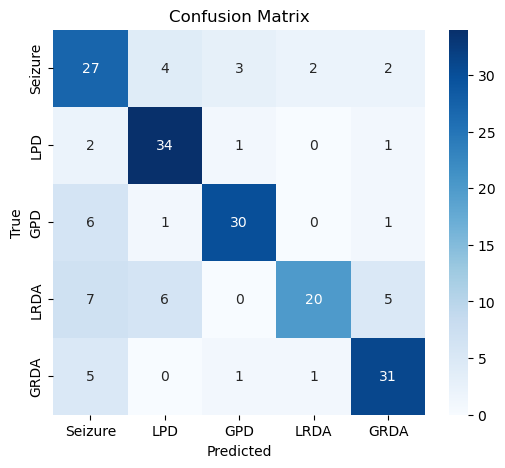

Classification Report:

              precision    recall  f1-score   support

     Seizure       0.57      0.71      0.64        38
         LPD       0.76      0.89      0.82        38
         GPD       0.86      0.79      0.82        38
        LRDA       0.87      0.53      0.66        38
        GRDA       0.78      0.82      0.79        38

    accuracy                           0.75       190
   macro avg       0.77      0.75      0.75       190
weighted avg       0.77      0.75      0.75       190



In [ ]:
class EEGScalogramResNet(nn.Module):
    def __init__(self, n_classes, in_channels=3):
        super().__init__()
        self.base_model = resnet18(weights=None)
        self.base_model.conv1 = nn.Conv2d(in_channels, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.base_model.fc = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(self.base_model.fc.in_features, n_classes)
        )

    def forward(self, x):
        return self.base_model(x)
    
# Device Setting
device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")

# Initialise and Load the Model
model = EEGScalogramResNet(n_classes = 5, in_channels = 3).to(device)
model.load_state_dict(torch.load("./models/ResNet18_scalobandpass_v7.pth", map_location = device))
model.eval()

def clean_tensor(x):
    x = torch.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)
    return torch.clamp(x, -1e6, 1e6)

X_test_bp_sc = clean_tensor(X_test_bp_sc)
test_loader = DataLoader(TensorDataset(X_test_bp_sc, y_test_bp_sc), batch_size=32)

all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        preds = outputs.argmax(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Confusion Matrix
labels_list = ['Seizure', 'LPD', 'GPD', 'LRDA', 'GRDA']
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels_list, yticklabels=labels_list)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

# Classification Report
print("Classification Report:\n")
print(classification_report(all_labels, all_preds, target_names=labels_list))